# 05 — Perbandingan Akhir Ketiga Metode

Notebook ini membandingkan user-based CF, item-based CF, dan matrix factorization pada kelima fold yang
sama, ditambah empat **baseline** (metode pembanding yang sangat sederhana):

| Baseline | Cara menebak rating |
|---|---|
| Tebak acak | angka acak antara 1 dan 5 |
| Rata-rata global | selalu rata-rata seluruh rating |
| Rata-rata user | rata-rata rating milik user tersebut |
| Rata-rata film | rata-rata rating film tersebut |

Baseline penting sebagai patokan: sebuah metode baru bisa disebut berguna jika hasilnya **jelas lebih baik**
daripada tebakan sesederhana ini.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import plot_style as ps
ps.setup()
pd.set_option("display.precision", 4)
import time
from scipy import stats
from src.data import load_fold, load_ratings, load_items, to_matrix, unique_titles
from src.metrics import evaluate, mae
from src.ubcf import UserBasedCF
from src.ibcf import ItemBasedCF
from src.mf import MatrixFactorization
from src.baseline import RandomGuess, GlobalMean, UserMean, ItemMean

cfg = pd.read_csv(RES / "mf_config.csv", index_col=0)["nilai"]
MF_K, MF_ALPHA, MF_BETA, MF_EPOCHS = int(cfg["K"]), float(cfg["alpha"]), float(cfg["beta"]), int(cfg["epochs"])

METODE = {
    "Tebak acak": lambda: RandomGuess(),
    "Rata-rata global": lambda: GlobalMean(),
    "Rata-rata user": lambda: UserMean(),
    "Rata-rata film": lambda: ItemMean(),
    "User-based CF": lambda: UserBasedCF(k=30, sig_weight=50),
    "Item-based CF": lambda: ItemBasedCF(k=30, adjusted=True, sig_weight=50),
    "Matrix factorization": lambda: MatrixFactorization(K=MF_K, alpha=MF_ALPHA, beta=MF_BETA, epochs=MF_EPOCHS),
}
UTAMA = ["User-based CF", "Item-based CF", "Matrix factorization"]
WARNA = {"User-based CF": ps.BLUE, "Item-based CF": ps.ORANGE, "Matrix factorization": ps.AQUA}
ABU = "#8f8d86"

## 1. Menjalankan semua metode di kelima fold

Setiap metode dilatih ulang di setiap fold dengan konfigurasi akhir dari notebook 02–04. Waktu pelatihan
dan prediksi juga dicatat. Bagian ini butuh sekitar 3–4 menit (terutama matrix factorization).

In [2]:
hasil, waktu, prediksi = [], [], []
for k in range(1, 6):
    train, test = load_fold(k)
    R = to_matrix(train)
    n_rating_film = (~np.isnan(R)).sum(axis=0)
    for nama, buat in METODE.items():
        t0 = time.perf_counter(); model = buat().fit(R)
        t1 = time.perf_counter(); p = model.predict_df(test)
        t2 = time.perf_counter()
        hasil.append({"Metode": nama, "Fold": k, **evaluate(p)})
        waktu.append({"Metode": nama, "Fold": k, "Latih (detik)": t1 - t0, "Prediksi (detik)": t2 - t1})
        if nama in UTAMA + ["Rata-rata film"]:
            prediksi.append(p.assign(Metode=nama, Fold=k,
                                     rating_film_latih=n_rating_film[test["item"].to_numpy() - 1])
                             [["Metode", "Fold", "user", "item", "rating", "pred", "rating_film_latih"]])
hasil = pd.DataFrame(hasil)
waktu = pd.DataFrame(waktu)
prediksi = pd.concat(prediksi, ignore_index=True)
print("selesai:", len(hasil), "kombinasi metode x fold")

selesai: 35 kombinasi metode x fold


Sebagai pemeriksaan, angka di sini harus sama dengan hasil 5-fold yang disimpan oleh notebook 02, 03, dan 04.

In [3]:
for nama, f in [("User-based CF", "ubcf_5fold.csv"), ("Item-based CF", "ibcf_5fold.csv"), ("Matrix factorization", "mf_5fold.csv")]:
    lama = pd.read_csv(RES / f, index_col=0).iloc[:5][["MAE", "RMSE", "NDCG@10"]].to_numpy()
    baru = hasil[hasil["Metode"] == nama].sort_values("Fold")[["MAE", "RMSE", "NDCG@10"]].to_numpy()
    print(f"{nama:22s} sama dengan notebook sebelumnya: {np.allclose(lama, baru)}")

User-based CF          sama dengan notebook sebelumnya: True
Item-based CF          sama dengan notebook sebelumnya: True
Matrix factorization   sama dengan notebook sebelumnya: True


## 2. Tabel perbandingan (rata-rata ± simpangan baku 5 fold)

In [4]:
METRIK = ["MAE", "MSE", "RMSE", "NMSE", "NDCG@10"]
urut = list(METODE)
rata = hasil.groupby("Metode")[METRIK].mean().loc[urut]
sd = hasil.groupby("Metode")[METRIK].std().loc[urut]
rata.to_csv(RES / "perbandingan_rata2.csv")
sd.to_csv(RES / "perbandingan_sd.csv")
tabel = rata.round(4).astype(str) + " ± " + sd.round(4).astype(str)
tabel

,MAE,MSE,RMSE,NMSE,NDCG@10
Metode,,,,,
Tebak acak,1.3902 ± 0.0167,2.8901 ± 0.0634,1.6999 ± 0.0186,0.7225 ± 0.0158,0.6839 ± 0.0275
Rata-rata global,0.9447 ± 0.0146,1.2672 ± 0.0394,1.1256 ± 0.0174,0.3168 ± 0.0099,0.7366 ± 0.0177
Rata-rata user,0.8362 ± 0.009,1.0895 ± 0.025,1.0437 ± 0.0119,0.2724 ± 0.0062,0.7366 ± 0.0177
Rata-rata film,0.8174 ± 0.0068,1.0498 ± 0.0146,1.0246 ± 0.0071,0.2624 ± 0.0036,0.8329 ± 0.0087
User-based CF,0.7342 ± 0.0047,0.8901 ± 0.0114,0.9434 ± 0.006,0.2225 ± 0.0029,0.8474 ± 0.0088
Item-based CF,0.7383 ± 0.0086,0.8949 ± 0.0207,0.9459 ± 0.0109,0.2237 ± 0.0052,0.8375 ± 0.0064
Matrix factorization,0.7357 ± 0.0052,0.8554 ± 0.0097,0.9249 ± 0.0052,0.2138 ± 0.0024,0.8578 ± 0.0057


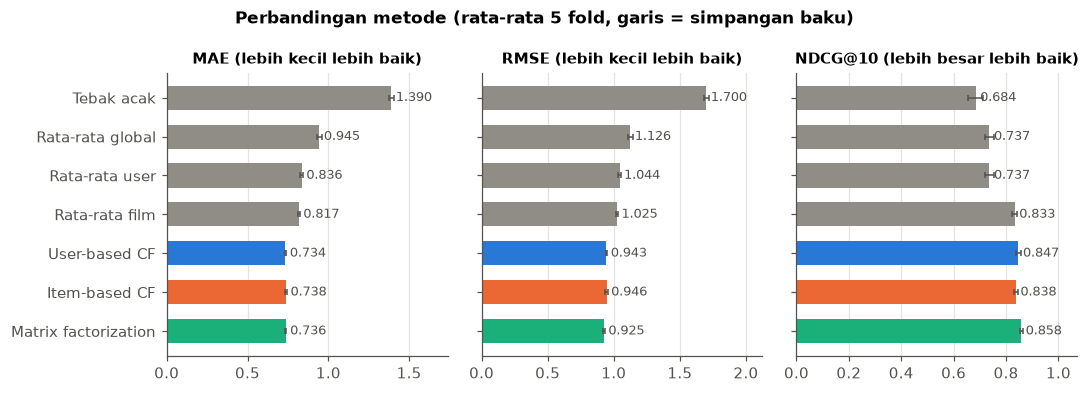

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
for ax, m in zip(axes, ["MAE", "RMSE", "NDCG@10"]):
    nilai = rata[m]
    warna = [WARNA.get(n, ABU) for n in nilai.index]
    ax.barh(nilai.index, nilai.values, color=warna, height=0.62, xerr=sd[m].values,
            error_kw={"ecolor": ps.INK_2, "elinewidth": 1, "capsize": 2})
    for y, v in enumerate(nilai.values):
        ax.text(v + nilai.max() * 0.02, y, f"{v:.3f}", va="center", fontsize=8.5, color=ps.INK_2)
    ax.set_title(m + (" (lebih kecil lebih baik)" if m != "NDCG@10" else " (lebih besar lebih baik)"), fontsize=9.5)
    ax.set_xlim(0, nilai.max() * 1.25)
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.suptitle("Perbandingan metode (rata-rata 5 fold, garis = simpangan baku)", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "perbandingan_metrik.png")
plt.show()

## 3. Seberapa jauh lebih baik dari baseline?

Persentase perbaikan dihitung terhadap baseline terkuat untuk setiap metrik. Untuk MAE dan RMSE (lebih kecil
lebih baik):

$$\text{perbaikan} = \frac{\text{baseline} - \text{metode}}{\text{baseline}} \times 100\%$$

Untuk NDCG (lebih besar lebih baik), pembilangnya dibalik: metode − baseline.

In [6]:
baris = []
for m in ["MAE", "RMSE", "NDCG@10"]:
    besar_lebih_baik = m == "NDCG@10"
    base = rata.loc[["Rata-rata global", "Rata-rata user", "Rata-rata film"], m]
    nama_base = base.idxmax() if besar_lebih_baik else base.idxmin()
    b = base[nama_base]
    for n in UTAMA:
        v = rata.loc[n, m]
        persen = (v - b) / b * 100 if besar_lebih_baik else (b - v) / b * 100
        baris.append({"Metrik": m, "Baseline terkuat": nama_base, "Nilai baseline": b,
                      "Metode": n, "Nilai metode": v, "Perbaikan (%)": persen})
perbaikan = pd.DataFrame(baris)
perbaikan.to_csv(RES / "perbaikan_vs_baseline.csv", index=False)
perbaikan.pivot(index="Metode", columns="Metrik", values="Perbaikan (%)").loc[UTAMA].round(2)

Metrik,MAE,NDCG@10,RMSE
Metode,,,
User-based CF,10.18,1.74,7.92
Item-based CF,9.68,0.55,7.67
Matrix factorization,10.00,2.99,9.73


In [7]:
b = perbaikan.query("Metrik == 'RMSE' and Metode == 'Matrix factorization'").iloc[0]
print("Contoh perhitungan (RMSE, matrix factorization):")
print(f"  baseline terkuat = {b['Baseline terkuat']} = {b['Nilai baseline']:.4f}")
print(f"  perbaikan = ({b['Nilai baseline']:.4f} - {b['Nilai metode']:.4f}) / {b['Nilai baseline']:.4f} x 100% = {b['Perbaikan (%)']:.2f}%")

Contoh perhitungan (RMSE, matrix factorization):
  baseline terkuat = Rata-rata film = 1.0246
  perbaikan = (1.0246 - 0.9249) / 1.0246 x 100% = 9.73%


## 4. Memahami nilai NDCG

NDCG ketiga metode berada di sekitar 0,84–0,86, terlihat tinggi. Tetapi baseline juga sudah tinggi:

- Mengurutkan film secara **acak** saja sudah memberi NDCG@10 sekitar 0,68.
- Mengurutkan berdasarkan **rata-rata rating film** memberi sekitar 0,83.

Penyebabnya, NDCG dihitung dengan mengurutkan film-film milik user di data uji, dan lebih dari separuh rating
di dataset bernilai ≥ 4 (relevan). Jadi bahkan urutan acak pun banyak menempatkan film relevan di posisi atas.
Angka NDCG di sini hanya bermakna jika **dibandingkan antar-metode** pada cara hitung yang sama.

In [8]:
rel = prediksi.query("Metode == 'User-based CF'").assign(relevan=lambda d: d["rating"] >= 4)
per_user = rel.groupby(["Fold", "user"])["relevan"].mean()
print(f"Rata-rata proporsi film relevan per user di data uji: {per_user.mean():.2%}")

# Rata-rata global dan rata-rata user memberi skor sama untuk semua film milik seorang user,
# sehingga urutannya ditentukan oleh id film (aturan pemecah seri). Apakah id film berkaitan dengan popularitas?
semua = load_ratings()
per_film = semua.groupby("item")["rating"].agg(["count", "mean"])
rho_n, _ = stats.spearmanr(per_film.index, per_film["count"])
rho_m, _ = stats.spearmanr(per_film.index, per_film["mean"])
print(f"Korelasi Spearman id film vs jumlah rating : {rho_n:.3f}")
print(f"Korelasi Spearman id film vs rata-rata rating: {rho_m:.3f}")

Rata-rata proporsi film relevan per user di data uji: 57.94%
Korelasi Spearman id film vs jumlah rating : -0.806
Korelasi Spearman id film vs rata-rata rating: -0.394


**Mengapa baseline rata-rata global dan rata-rata user punya NDCG yang sama (0,7366), dan lebih tinggi dari acak?**
Kedua baseline memberi skor yang sama untuk semua film milik seorang user, sehingga urutannya ditentukan oleh
aturan pemecah seri, yaitu id film (id kecil di depan). Ternyata id film di MovieLens berkorelasi kuat dengan
popularitas (Spearman −0,806: makin kecil id, makin banyak rating) dan cukup berkorelasi dengan rata-rata
rating (−0,394). Jadi tanpa disengaja, kedua baseline ini mengurutkan film populer lebih dulu, dan film populer
cenderung dinilai lebih tinggi. Itulah sebabnya hasilnya di atas tebakan acak.

## 5. Apakah perbedaan antar-metode berarti? (perbandingan per fold)

Selisih rata-rata saja belum cukup. Karena kelima metode diuji pada fold yang sama, kita bisa melihat
**di setiap fold** metode mana yang menang (perbandingan berpasangan).

In [9]:
pasangan = [("Matrix factorization", "User-based CF"), ("Matrix factorization", "Item-based CF"), ("User-based CF", "Item-based CF")]
baris = []
for m in ["MAE", "RMSE", "NDCG@10"]:
    piv = hasil.pivot(index="Fold", columns="Metode", values=m)
    for a, b in pasangan:
        d = piv[a] - piv[b]
        menang_a = (d > 0).sum() if m == "NDCG@10" else (d < 0).sum()
        t, pval = stats.ttest_rel(piv[a], piv[b])
        baris.append({"Metrik": m, "Perbandingan": f"{a} vs {b}", "Selisih rata-rata": d.mean(),
                      "Fold dimenangkan (dari 5)": f"{menang_a} : {5 - menang_a}", "p-value (uji t berpasangan)": pval})
uji = pd.DataFrame(baris)
uji.to_csv(RES / "uji_berpasangan.csv", index=False)
uji

,Metrik,Perbandingan,Selisih rata-rata,Fold dimenangkan (dari 5),p-value (uji t berpasangan)
0,MAE,Matrix factorization vs User-based CF,0.0015,2 : 3,0.4081
1,MAE,Matrix factorization vs Item-based CF,-0.0026,4 : 1,0.2657
2,MAE,User-based CF vs Item-based CF,-0.0041,4 : 1,0.1092
3,RMSE,Matrix factorization vs User-based CF,-0.0186,5 : 0,0.0002
4,RMSE,Matrix factorization vs Item-based CF,-0.0211,5 : 0,0.0020
5,RMSE,User-based CF vs Item-based CF,-0.0025,3 : 2,0.3839
6,NDCG@10,Matrix factorization vs User-based CF,0.0104,5 : 0,0.0102
7,NDCG@10,Matrix factorization vs Item-based CF,0.0203,5 : 0,0.0008
8,NDCG@10,User-based CF vs Item-based CF,0.0099,5 : 0,0.0138


Kolom *fold dimenangkan* dibaca "metode pertama : metode kedua". p-value di bawah 0,05 biasanya dianggap
perbedaan yang **signifikan secara statistik**, artinya kecil kemungkinan perbedaan itu hanya kebetulan.
Catatan: dengan hanya 5 fold, uji ini kurang peka, sehingga hasilnya dibaca sebagai petunjuk, bukan bukti mutlak.

## 6. Sebaran besar kesalahan

MAE dan RMSE bisa memberi urutan yang berbeda. RMSE mengkuadratkan kesalahan, sehingga sangat menghukum
kesalahan besar. Untuk melihatnya, kesalahan absolut |prediksi − aktual| dikelompokkan.

In [10]:
batas = [0, 0.5, 1, 2, 5]
label = ["< 0,5", "0,5 – 1", "1 – 2", "≥ 2"]
prediksi["error"] = (prediksi["pred"] - prediksi["rating"]).abs()
prediksi["kelompok_error"] = pd.cut(prediksi["error"], batas, labels=label, right=False, include_lowest=True)
sebaran = (prediksi[prediksi["Metode"].isin(UTAMA)]
           .groupby(["Metode", "kelompok_error"], observed=False).size()
           .unstack().loc[UTAMA])
sebaran_persen = sebaran.div(sebaran.sum(axis=1), axis=0) * 100
sebaran_persen.round(2)

kelompok_error,"< 0,5","0,5 – 1",1 – 2,≥ 2
Metode,,,,
User-based CF,42.74,30.34,22.83,4.10
Item-based CF,42.08,31.12,22.51,4.29
Matrix factorization,41.19,31.27,24.31,3.23


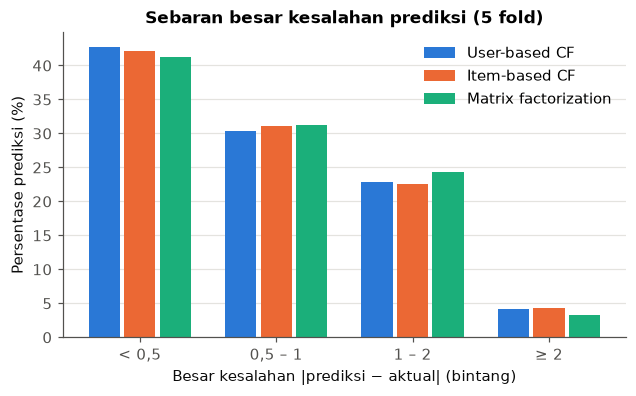

In [11]:
fig, ax = plt.subplots(figsize=(6.6, 3.6))
lebar = 0.26
x = np.arange(len(label))
for j, n in enumerate(UTAMA):
    ax.bar(x + (j - 1) * lebar, sebaran_persen.loc[n].values, width=lebar - 0.03, color=WARNA[n], label=n)
ax.set_xticks(x, label)
ax.set_xlabel("Besar kesalahan |prediksi − aktual| (bintang)")
ax.set_ylabel("Persentase prediksi (%)")
ax.set_title("Sebaran besar kesalahan prediksi (5 fold)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
fig.savefig(FIG / "sebaran_error.png")
plt.show()

## 7. Kesalahan pada film populer vs film jarang dirating

Ini menguji dampak *sparsity*: apakah prediksi untuk film yang jarang dirating lebih buruk? Film dikelompokkan
berdasarkan jumlah rating yang dimilikinya di data latih fold tersebut.

In [12]:
kel = [0, 10, 50, 150, 10_000]
lab = ["< 10", "10 – 49", "50 – 149", "≥ 150"]
prediksi["popularitas"] = pd.cut(prediksi["rating_film_latih"], kel, labels=lab, right=False)
pop = (prediksi.groupby(["Metode", "popularitas"], observed=False)
       .apply(lambda g: pd.Series({"MAE": mae(g["rating"], g["pred"]), "Jumlah prediksi": len(g)}))
       .reset_index())
pop_tabel = pop.pivot(index="popularitas", columns="Metode", values="MAE")[UTAMA + ["Rata-rata film"]]
pop_tabel["Jumlah prediksi"] = pop[pop["Metode"] == "User-based CF"].set_index("popularitas")["Jumlah prediksi"].astype(int)
pop_tabel.round(4)

Metode,User-based CF,Item-based CF,Matrix factorization,Rata-rata film,Jumlah prediksi
popularitas,,,,,
< 10,0.8415,0.9216,0.8464,1.0885,3080
10 – 49,0.7741,0.8044,0.7720,0.8744,18138
50 – 149,0.7325,0.7263,0.7307,0.8069,42670
≥ 150,0.7071,0.7036,0.7139,0.7781,36112


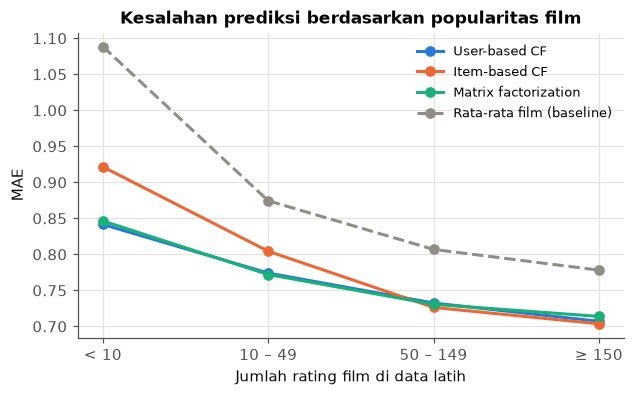

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for n in UTAMA:
    ax.plot(lab, pop_tabel[n].values, marker="o", color=WARNA[n], label=n)
ax.plot(lab, pop_tabel["Rata-rata film"].values, marker="o", color=ABU, linestyle="--", label="Rata-rata film (baseline)")
ax.set_xlabel("Jumlah rating film di data latih")
ax.set_ylabel("MAE")
ax.set_title("Kesalahan prediksi berdasarkan popularitas film")
ax.legend(loc="upper right", fontsize=8.5)
fig.savefig(FIG / "error_vs_popularitas.png")
plt.show()

## 8. Waktu komputasi (rata-rata per fold)

In [14]:
w = waktu.groupby("Metode")[["Latih (detik)", "Prediksi (detik)"]].mean().loc[UTAMA]
w["Total (detik)"] = w.sum(axis=1)
w.to_csv(RES / "waktu_komputasi.csv")
w.round(2)

,Latih (detik),Prediksi (detik),Total (detik)
Metode,,,
User-based CF,0.44,0.49,0.93
Item-based CF,0.32,0.46,0.78
Matrix factorization,33.72,0.01,33.73


Waktu ini diukur di laptop yang sama dan termasuk perhitungan matriks similarity (UBCF, IBCF) atau seluruh
epoch pelatihan (MF). Angkanya bergantung pada perangkat, tetapi perbandingan antar-metode tetap bermakna.

## 9. Rekomendasi untuk user yang sama dari ketiga metode

Ketiga model dilatih dengan seluruh data, lalu masing-masing memberi 10 rekomendasi untuk user 1.

In [15]:
titles = load_items()
R_full = to_matrix(load_ratings())
rated0 = ~np.isnan(R_full[0])
seen0 = np.flatnonzero(rated0)
u_full = UserBasedCF(k=30, sig_weight=50).fit(R_full)
i_full = ItemBasedCF(k=30, adjusted=True, sig_weight=50).fit(R_full)
m_full = MatrixFactorization(K=MF_K, alpha=MF_ALPHA, beta=MF_BETA, epochs=MF_EPOCHS).fit(R_full)
rek = {
    "User-based CF": unique_titles(u_full.recommend(0, n=40), titles, seen0),
    "Item-based CF": unique_titles(i_full.recommend(0, n=40), titles, seen0),
    "Matrix factorization": unique_titles(m_full.recommend(0, rated0, n=40), titles, seen0),
}
pd.DataFrame({n: [titles[i + 1] for i, _, _ in r] for n, r in rek.items()}, index=range(1, 11))

,User-based CF,Item-based CF,Matrix factorization
1,Pather Panchali (1955),Paris Is Burning (1990),"Close Shave, A (1995)"
2,"Close Shave, A (1995)",Ulee's Gold (1997),Pather Panchali (1955)
3,Casablanca (1942),Like Water For Chocolate (Como agua para choco...,"Third Man, The (1949)"
4,Faust (1994),When We Were Kings (1996),Faust (1994)
5,Schindler's List (1993),"Double vie de Véronique, La (Double Life of Ve...",Lawrence of Arabia (1962)
6,L.A. Confidential (1997),Casablanca (1942),Secrets & Lies (1996)
7,Secrets & Lies (1996),Duck Soup (1933),Dr. Strangelove or: How I Learned to Stop Worr...
8,Rear Window (1954),Brassed Off (1996),Ran (1985)
9,Dr. Strangelove or: How I Learned to Stop Worr...,My Life as a Dog (Mitt liv som hund) (1985),Down by Law (1986)
10,Lawrence of Arabia (1962),Kundun (1997),Rosencrantz and Guildenstern Are Dead (1990)


In [16]:
himpunan = {n: {i for i, _, _ in r} for n, r in rek.items()}
for a, b in pasangan:
    sama = himpunan[a] & himpunan[b]
    print(f"{a} & {b}: {len(sama)} film sama -> {[titles[i + 1] for i in sama]}")
print("Ada di ketiganya:", [titles[i + 1] for i in himpunan['User-based CF'] & himpunan['Item-based CF'] & himpunan['Matrix factorization']])

Matrix factorization & User-based CF: 6 film sama -> ['Pather Panchali (1955)', 'Faust (1994)', 'Close Shave, A (1995)', 'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963)', 'Secrets & Lies (1996)', 'Lawrence of Arabia (1962)']
Matrix factorization & Item-based CF: 0 film sama -> []
User-based CF & Item-based CF: 1 film sama -> ['Casablanca (1942)']
Ada di ketiganya: []


## Kesimpulan

**1. Ketiga metode jelas lebih baik daripada baseline dalam memprediksi rating.** Dibanding baseline terkuat
(rata-rata rating film), MAE turun sekitar 9,7–10,2% dan RMSE turun 7,7–9,7%. Matrix factorization memberi
perbaikan RMSE terbesar (1,0246 → 0,9249, atau 9,73%).

**2. Untuk urutan rekomendasi (NDCG), keunggulan atas baseline kecil.** Mengurutkan film berdasarkan
rata-rata ratingnya saja sudah mencapai NDCG@10 = 0,8329. Ketiga metode hanya menambah 0,5–3,0% di atasnya.
Ini wajar, karena NDCG dihitung pada film-film di data uji yang sekitar 58% di antaranya relevan.

**3. Matrix factorization terbaik untuk RMSE dan NDCG, dan perbedaannya konsisten.** MF menang di kelima fold
untuk RMSE (p = 0,0002 terhadap UBCF dan p = 0,0020 terhadap IBCF) dan untuk NDCG@10 (p = 0,0102 dan 0,0008).

**4. Untuk MAE, ketiga metode praktis setara.** Selisihnya hanya 0,0015–0,0041, pemenangnya berganti-ganti antar
fold, dan tidak ada yang signifikan (p > 0,1). Sebaran kesalahan menjelaskan perbedaan MAE dan RMSE: MF paling
jarang membuat kesalahan besar ≥ 2 bintang (3,23%, dibanding 4,10% UBCF dan 4,29% IBCF), tetapi juga sedikit
lebih jarang membuat tebakan yang sangat tepat (< 0,5 bintang: 41,19% vs 42,74% UBCF). Karena RMSE
mengkuadratkan kesalahan, MF unggul di RMSE; karena MAE tidak, hasil ketiganya mirip.

**5. User-based dan item-based CF hampir sama.** Selisih MAE dan RMSE tidak signifikan, tetapi UBCF menang di
kelima fold untuk NDCG@10 (p = 0,0138).

**6. Semua metode kesulitan pada film yang jarang dirating (sparsity).** MAE untuk film dengan < 10 rating
sekitar 0,84–0,92, jauh di atas film dengan ≥ 150 rating (0,70–0,71). Item-based CF paling terpengaruh
(MAE 0,9216), karena kemiripan sebuah film hanya bisa dihitung dari sedikit user. Sebaliknya, untuk film
populer item-based CF justru sedikit paling baik (0,7036).

**7. Pertimbangan praktis.** UBCF dan IBCF dilatih dalam kurang dari 0,5 detik, sedangkan MF butuh sekitar
34 detik per fold. Namun setelah dilatih, MF memprediksi 20.000 rating hanya dalam 0,01 detik (satu perkalian
matriks), sehingga paling cocok untuk sistem yang harus menjawab cepat.

**8. Rekomendasi yang dihasilkan berbeda karakter.** Untuk user 1, MF dan UBCF berbagi 6 dari 10 film,
sedangkan IBCF tidak berbagi satu pun film dengan MF. IBCF cenderung merekomendasikan film yang mirip dengan
film spesifik yang pernah ditonton user, sedangkan UBCF dan MF memakai pola selera secara keseluruhan.